Samples used: 500  Features: 16
Linear  Shape = (500, 500)  Min = 1.4169  Max = 8.876  Symmetric = True
Polynomial  Shape = (500, 500)  Min = 1.2899  Max = 3.7582  Symmetric = True
RBF  Shape = (500, 500)  Min = 0.6032  Max = 1.0  Symmetric = True


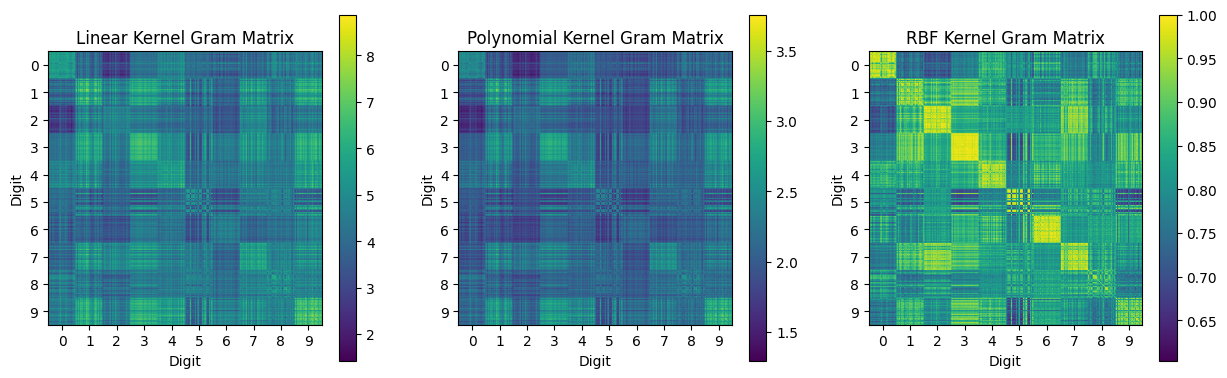

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import linear_kernel, polynomial_kernel, rbf_kernel

data = np.loadtxt("Datasets/pendigits.tra", delimiter=",")
Xall = data[:, :16] / 100
yall = data[:, 16].astype(int)

idx = []
for d in range(10):
    idx.extend(np.where(yall == d)[0][:50])
X = Xall[idx]
y = yall[idx]

print("Samples used:", X.shape[0], " Features:", X.shape[1])

K_lin = linear_kernel(X)
K_poly = polynomial_kernel(X, degree=3)
K_rbf = rbf_kernel(X)

kernels = [("Linear", K_lin), ("Polynomial", K_poly), ("RBF", K_rbf)]
for name, K in kernels:
    print(name, " Shape =", K.shape, " Min =", round(K.min(), 4), " Max =", round(K.max(), 4), " Symmetric =", np.allclose(K, K.T))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for i in range(3):
    name, K = kernels[i]
    im = ax[i].imshow(K)
    ax[i].set_title(name + " Kernel Gram Matrix")
    ax[i].set_xticks(np.arange(25, 500, 50))
    ax[i].set_xticklabels(range(10))
    ax[i].set_yticks(np.arange(25, 500, 50))
    ax[i].set_yticklabels(range(10))
    ax[i].set_xlabel("Digit")
    ax[i].set_ylabel("Digit")
    fig.colorbar(im, ax=ax[i])
plt.show()
